In [39]:
import pandas as pd

In [40]:
df=pd.read_csv('Steel_industry_data.csv')

In [41]:
df

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.00,0.0,73.21,100.00,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.00,0.0,66.77,100.00,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.00,0.0,70.28,100.00,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.00,0.0,68.09,100.00,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.00,0.0,64.72,100.00,4500,Weekday,Monday,Light_Load
...,...,...,...,...,...,...,...,...,...,...,...
35035,31/12/2018 23:00,3.85,4.86,0.00,0.0,62.10,100.00,82800,Weekday,Monday,Light_Load
35036,31/12/2018 23:15,3.74,3.74,0.00,0.0,70.71,100.00,83700,Weekday,Monday,Light_Load
35037,31/12/2018 23:30,3.78,3.17,0.07,0.0,76.62,99.98,84600,Weekday,Monday,Light_Load
35038,31/12/2018 23:45,3.78,3.06,0.11,0.0,77.72,99.96,85500,Weekday,Monday,Light_Load


In [42]:
df.isna().sum()

date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  str    
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  str    
 9   Day_of_week                           35040 non-null  str    
 10  Load_Type                             35040 non-null  str    
dtypes: float64(6), int64(1), s

In [44]:
df.describe()

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000
mean,27.386892,13.035384,3.870949,0.011524,80.578056,84.367870,42750.000000
std,33.444380,16.306000,7.424463,0.016151,18.921322,30.456535,24940.534317
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.200000,2.300000,0.000000,0.000000,63.320000,99.700000,21375.000000
50%,4.570000,5.000000,0.000000,0.000000,87.960000,100.000000,42750.000000
75%,51.237500,22.640000,2.090000,0.020000,99.022500,100.000000,64125.000000
max,157.180000,96.910000,27.760000,0.070000,100.000000,100.000000,85500.000000


In [45]:
df['date'] = pd.to_datetime(df['date'], dayfirst=True)
df['hour'] = df['date'].dt.hour
df = df.drop(columns=['date'])

In [46]:
import numpy as np
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

In [47]:
df

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,hour,hour_sin,hour_cos
0,3.17,2.95,0.00,0.0,73.21,100.00,900,Weekday,Monday,Light_Load,0,0.000000,1.000000
1,4.00,4.46,0.00,0.0,66.77,100.00,1800,Weekday,Monday,Light_Load,0,0.000000,1.000000
2,3.24,3.28,0.00,0.0,70.28,100.00,2700,Weekday,Monday,Light_Load,0,0.000000,1.000000
3,3.31,3.56,0.00,0.0,68.09,100.00,3600,Weekday,Monday,Light_Load,1,0.258819,0.965926
4,3.82,4.50,0.00,0.0,64.72,100.00,4500,Weekday,Monday,Light_Load,1,0.258819,0.965926
...,...,...,...,...,...,...,...,...,...,...,...,...,...
35035,3.85,4.86,0.00,0.0,62.10,100.00,82800,Weekday,Monday,Light_Load,23,-0.258819,0.965926
35036,3.74,3.74,0.00,0.0,70.71,100.00,83700,Weekday,Monday,Light_Load,23,-0.258819,0.965926
35037,3.78,3.17,0.07,0.0,76.62,99.98,84600,Weekday,Monday,Light_Load,23,-0.258819,0.965926
35038,3.78,3.06,0.11,0.0,77.72,99.96,85500,Weekday,Monday,Light_Load,23,-0.258819,0.965926


In [48]:
df=pd.get_dummies(df,columns=['Day_of_week','Load_Type'])

In [49]:
df

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,hour,hour_sin,...,Day_of_week_Friday,Day_of_week_Monday,Day_of_week_Saturday,Day_of_week_Sunday,Day_of_week_Thursday,Day_of_week_Tuesday,Day_of_week_Wednesday,Load_Type_Light_Load,Load_Type_Maximum_Load,Load_Type_Medium_Load
0,3.17,2.95,0.00,0.0,73.21,100.00,900,Weekday,0,0.000000,...,False,True,False,False,False,False,False,True,False,False
1,4.00,4.46,0.00,0.0,66.77,100.00,1800,Weekday,0,0.000000,...,False,True,False,False,False,False,False,True,False,False
2,3.24,3.28,0.00,0.0,70.28,100.00,2700,Weekday,0,0.000000,...,False,True,False,False,False,False,False,True,False,False
3,3.31,3.56,0.00,0.0,68.09,100.00,3600,Weekday,1,0.258819,...,False,True,False,False,False,False,False,True,False,False
4,3.82,4.50,0.00,0.0,64.72,100.00,4500,Weekday,1,0.258819,...,False,True,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35035,3.85,4.86,0.00,0.0,62.10,100.00,82800,Weekday,23,-0.258819,...,False,True,False,False,False,False,False,True,False,False
35036,3.74,3.74,0.00,0.0,70.71,100.00,83700,Weekday,23,-0.258819,...,False,True,False,False,False,False,False,True,False,False
35037,3.78,3.17,0.07,0.0,76.62,99.98,84600,Weekday,23,-0.258819,...,False,True,False,False,False,False,False,True,False,False
35038,3.78,3.06,0.11,0.0,77.72,99.96,85500,Weekday,23,-0.258819,...,False,True,False,False,False,False,False,True,False,False


In [50]:
df=pd.get_dummies(df,columns=['WeekStatus'])

In [51]:
df

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,hour,hour_sin,hour_cos,...,Day_of_week_Saturday,Day_of_week_Sunday,Day_of_week_Thursday,Day_of_week_Tuesday,Day_of_week_Wednesday,Load_Type_Light_Load,Load_Type_Maximum_Load,Load_Type_Medium_Load,WeekStatus_Weekday,WeekStatus_Weekend
0,3.17,2.95,0.00,0.0,73.21,100.00,900,0,0.000000,1.000000,...,False,False,False,False,False,True,False,False,True,False
1,4.00,4.46,0.00,0.0,66.77,100.00,1800,0,0.000000,1.000000,...,False,False,False,False,False,True,False,False,True,False
2,3.24,3.28,0.00,0.0,70.28,100.00,2700,0,0.000000,1.000000,...,False,False,False,False,False,True,False,False,True,False
3,3.31,3.56,0.00,0.0,68.09,100.00,3600,1,0.258819,0.965926,...,False,False,False,False,False,True,False,False,True,False
4,3.82,4.50,0.00,0.0,64.72,100.00,4500,1,0.258819,0.965926,...,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35035,3.85,4.86,0.00,0.0,62.10,100.00,82800,23,-0.258819,0.965926,...,False,False,False,False,False,True,False,False,True,False
35036,3.74,3.74,0.00,0.0,70.71,100.00,83700,23,-0.258819,0.965926,...,False,False,False,False,False,True,False,False,True,False
35037,3.78,3.17,0.07,0.0,76.62,99.98,84600,23,-0.258819,0.965926,...,False,False,False,False,False,True,False,False,True,False
35038,3.78,3.06,0.11,0.0,77.72,99.96,85500,23,-0.258819,0.965926,...,False,False,False,False,False,True,False,False,True,False


In [52]:
x=df.drop(['Usage_kWh'], axis=1)
y=df['Usage_kWh']

In [53]:
from sklearn.preprocessing import StandardScaler , MinMaxScaler , RobustScaler

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
x_train , x_test , y_train , y_test =train_test_split(x , y , )

In [56]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](21,)","[ 1.43, 0.02, 0.02,..., 2.91,-0.42, 0.42]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](21,)","['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh','CO2(tCO2)',..., 'Load_Type_Medium_Load','WeekStatus_Weekday','WeekStatus_Weekend']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-59.51
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,21
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [57]:
y_pred=model.predict(x_test)

In [58]:
print(y_pred,y_test)

[-5.27290265 98.33639526 75.18797457 ... 94.38687356 -2.44830222
  1.19736433] 21524      2.74
17702    116.06
9680     105.19
9155      61.92
11503      3.82
          ...  
32201      3.64
33595      5.44
30375    106.42
15390      2.84
16038      2.74
Name: Usage_kWh, Length: 8760, dtype: float64


In [59]:
from sklearn.linear_model import Lasso
model=Lasso()
model.fit(x_train , y_train)


,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [61]:
y_pred=model.predict(x_test)
print(y_pred ,y_test)

[-5.55329067 98.76577786 75.35054268 ... 92.81605697 -3.52167299
 -1.43879296] 21524      2.74
17702    116.06
9680     105.19
9155      61.92
11503      3.82
          ...  
32201      3.64
33595      5.44
30375    106.42
15390      2.84
16038      2.74
Name: Usage_kWh, Length: 8760, dtype: float64


In [62]:
from sklearn.linear_model import Ridge
model=Ridge()
model.fit(x_train,y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [64]:
y_pred=model.predict(x_test)
print(y_pred,y_test)

[ -2.56560618 101.50420993  85.47476026 ...  98.94120741  -0.70088445
   1.83135303] 21524      2.74
17702    116.06
9680     105.19
9155      61.92
11503      3.82
          ...  
32201      3.64
33595      5.44
30375    106.42
15390      2.84
16038      2.74
Name: Usage_kWh, Length: 8760, dtype: float64


In [66]:
from sklearn.linear_model import ElasticNet
model=ElasticNet()
model.fit(x_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",1.0
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [67]:
y_pred=model.predict(x_test)
print(y_pred , y_test)

[-5.56769324 98.67188843 75.34928321 ... 92.77656464 -3.62817104
 -1.22665345] 21524      2.74
17702    116.06
9680     105.19
9155      61.92
11503      3.82
          ...  
32201      3.64
33595      5.44
30375    106.42
15390      2.84
16038      2.74
Name: Usage_kWh, Length: 8760, dtype: float64


In [68]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [69]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(x_test)
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2  :", r2_score(y_test, y_pred))

MAE : 6.75886116903746
RMSE: 9.726007295085331
R2  : 0.9157743618491282


In [71]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "DecisionTree": DecisionTreeRegressor(random_state=42),
    "RandomForest": RandomForestRegressor(random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "KNN": KNeighborsRegressor(),
}

In [73]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []
preds = {}  

for name, m in models.items():
    m.fit(x_train, y_train)
    p = m.predict(x_test)
    preds[name] = p
    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p),
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
print(results_df)
print("بهترین مدل:", results_df.loc[0, "model"])

              model       MAE      RMSE        R2
0      RandomForest  0.348053  1.121810  0.998879
1      DecisionTree  0.564942  1.553728  0.997851
2  GradientBoosting  1.761153  2.926426  0.992375
3               KNN  1.745334  4.073780  0.985224
4             Ridge  4.599484  6.706245  0.959956
5            Linear  6.584205  9.323934  0.922594
6             Lasso  6.816291  9.780340  0.914831
بهترین مدل: RandomForest


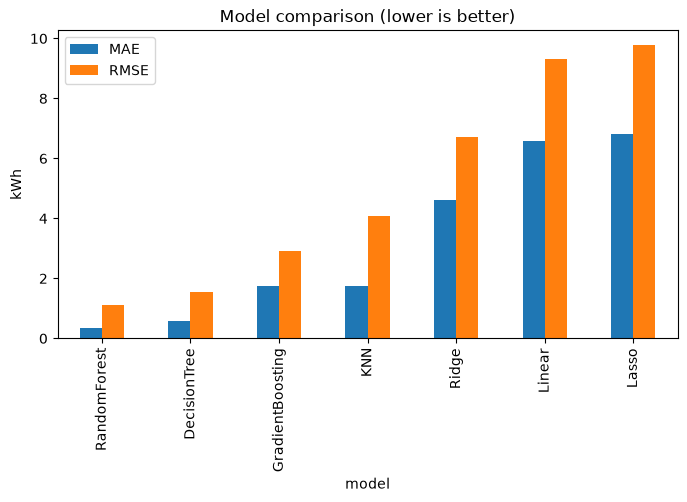

In [74]:
import matplotlib.pyplot as plt

results_df.set_index("model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(8,4))
plt.title("Model comparison (lower is better)")
plt.ylabel("kWh")
plt.show()

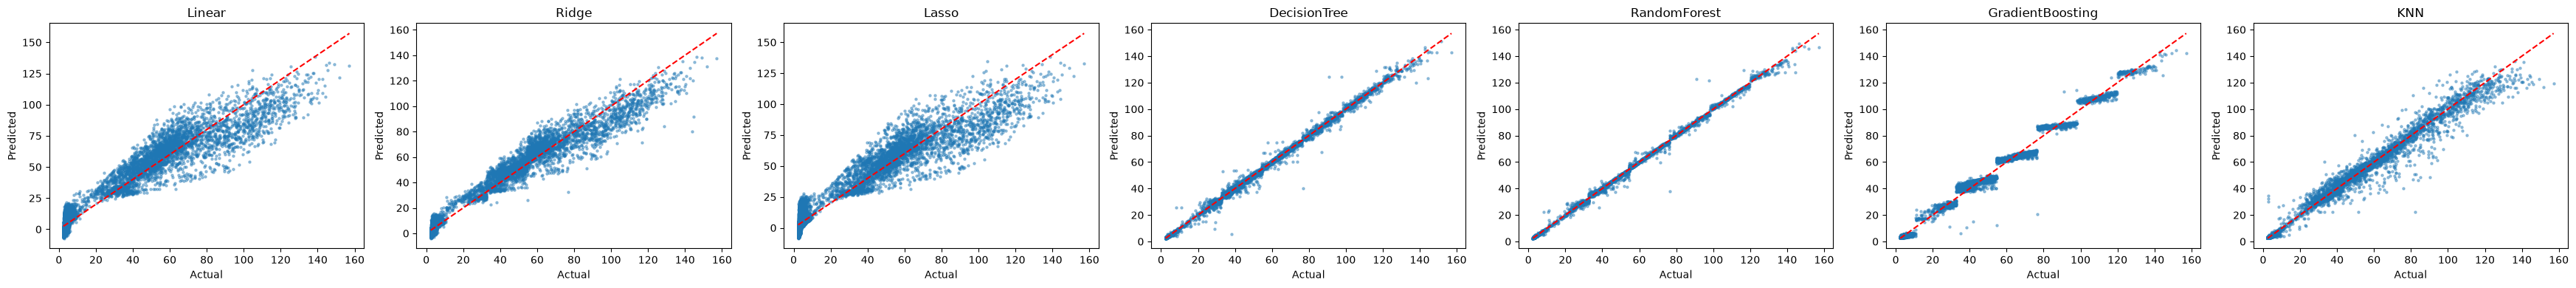

In [75]:
fig, axes = plt.subplots(1, len(preds), figsize=(5*len(preds), 4))
for ax, (name, p) in zip(np.atleast_1d(axes), preds.items()):
    ax.scatter(y_test, p, s=5, alpha=0.4)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "r--")   
    ax.set_title(name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
plt.tight_layout()
plt.show()

In [80]:
from tensorflow import keras 
from tensorflow.keras import layers

In [76]:
from sklearn.model_selection import train_test_split

In [77]:
x=df.drop(['Usage_kWh'], axis=1)
y=df['Usage_kWh']

In [78]:
x_train , x_test , y_train , y_test=train_test_split(x,y,test_size=0.2 ,random_state=42)

In [79]:
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [81]:
model=keras.Sequential([
    keras.layers.Input(shape=(x_train.shape[1],)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32,activation='relu'),
    keras.layers.Dense(16,activation='relu'),
    keras.layers.Dense(8,activation='relu'),
    keras.layers.Dense(1)
])

In [82]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mse']
)

In [83]:
history=model.fit(
    x_train,y_train,
    epochs=100,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 411.3851 - mse: 411.3851 - val_loss: 24.6424 - val_mse: 24.6424
Epoch 2/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step - loss: 14.8219 - mse: 14.8219 - val_loss: 18.8140 - val_mse: 18.8140
Epoch 3/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 453us/step - loss: 11.6418 - mse: 11.6418 - val_loss: 16.3454 - val_mse: 16.3454
Epoch 4/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 499us/step - loss: 10.1872 - mse: 10.1872 - val_loss: 14.6050 - val_mse: 14.6050
Epoch 5/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step - loss: 9.0350 - mse: 9.0350 - val_loss: 13.2275 - val_mse: 13.2275
Epoch 6/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 496us/step - loss: 7.8885 - mse: 7.8885 - val_loss: 11.7003 - val_mse: 11.7003
Epoch 7/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 490us/step - loss: 6.6561 - mse: 6.6561 - val_loss: 9.1626 - val_mse: 9.1626
Epoch 8/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 482us/step - loss: 5.5012 - mse: 5.5012 - val_loss: 6.8240 - val_mse: 6.8240
Epoch 9/100


In [84]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,485 (48.77 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,324 (32.52 KB)

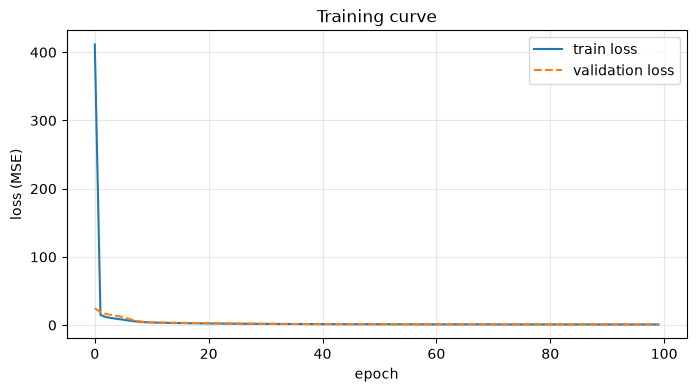

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss", linestyle="--")
plt.xlabel("epoch")
plt.ylabel("loss (MSE)")
plt.title("Training curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 197us/step


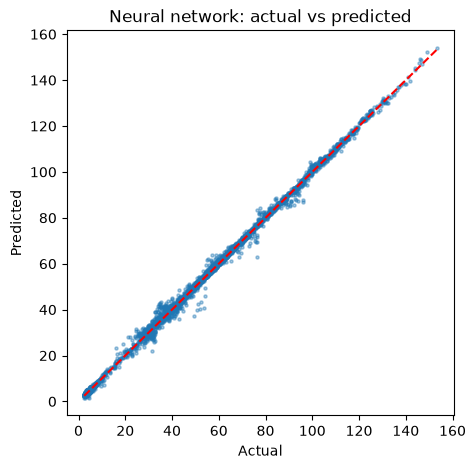

In [87]:
p = model.predict(x_test).ravel()

plt.figure(figsize=(5, 5))
plt.scatter(y_test, p, s=5, alpha=0.4)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Neural network: actual vs predicted")
plt.show()